In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
#from utils import *
#from utils_cpdir import *
from utils_mvcp import *
from utils import *
import os
from tqdm import tqdm

In [2]:
rebecca_data_ir = pd.read_csv('processed_data_new/rebecca_data_ir_final.csv')
del rebecca_data_ir['Unnamed: 0']
rebecca_data_ir.columns = list(np.float64(rebecca_data_ir.columns[:-4])) + list(rebecca_data_ir.columns[-4:])

rebecca_data_raman = pd.read_csv('processed_data_new/rebecca_data_raman_final_als.csv')
del rebecca_data_raman['Unnamed: 0']
rebecca_data_raman.columns = list(np.float64(rebecca_data_raman.columns[:-4])) + list(rebecca_data_raman.columns[-4:])

In [3]:
np.unique(rebecca_data_raman['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [118]:
poly_abbr_table = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:9,-5:-3]
poly_abbr_table.columns = ['polymer', 'abbr']

poly_and_comments_list = pd.read_excel('data_new/CCOPTIR_20240604_MixedMPsStdsv2_RP_mIRage_allccdata_manualsort.xlsx',
         sheet_name='Other cc data and sort').iloc[:,9:13]

poly_list = list(np.unique(rebecca_data_raman['polymer'])) + ['LDPE']

IR_spectra_mix_std = pd.read_csv('processed_data_new/data_ir_mix_std_rebecca.csv')
del IR_spectra_mix_std['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix_std.columns = list(np.float64(IR_spectra_mix_std.columns[:-5])) + list(IR_spectra_mix_std.columns[-5:])

IR_spectra_mix_std = (IR_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(IR_spectra_mix_std.shape[1]-3))+[-1,-3,-2]])

IR_spectra_mix_std_rest = IR_spectra_mix_std.loc[[x not in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
#IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std = IR_spectra_mix_std.loc[[x in poly_list for x in IR_spectra_mix_std['polymer']],:].reset_index(drop=True)
IR_spectra_mix_std.loc[IR_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'

#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')
Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca_als.csv')
notes_mix_std_rest = np.array(Raman_spectra_mix_std['comments'])
notes_mix_std_rest[[x is np.nan for x in notes_mix_std_rest]] = ''
del Raman_spectra_mix_std['Unnamed: 0']
Raman_spectra_mix_std.columns = list(np.float64(Raman_spectra_mix_std.columns[:-7])) + list(Raman_spectra_mix_std.columns[-7:])
Raman_spectra_mix_std = (Raman_spectra_mix_std.
 merge(poly_abbr_table, left_on='polymer', right_on='abbr').
 drop(['polymer_x', 'abbr'],axis=1).
 rename({'polymer_y':'polymer'},axis=1).
iloc[:,list(range(Raman_spectra_mix_std.shape[1]-5))+[-1,-2]])

#poly_and_comments_list_rest = poly_and_comments_list.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

Raman_spectra_mix_std_rest = Raman_spectra_mix_std.loc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)

#poly_and_comments_list = poly_and_comments_list.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std = Raman_spectra_mix_std.loc[[x in poly_list for x in Raman_spectra_mix_std['polymer']],:].reset_index(drop=True)
Raman_spectra_mix_std.loc[Raman_spectra_mix_std['polymer'] == 'LDPE','polymer'] = 'PE'


In [119]:
notes_mix_std_rest

array(['', '', '', '', '', 'PSL AND SOMETHING ELSE? SCR?', '', '', '', '',
       '', '', '', '', '', '', 'AS AND LDPE?', '', '', 'PP AND LDPE?', '',
       'FLUORESCENCE, LDPE?', '', '', '', 'ODD PEAKS IN PTIR', '',
       'SCR AND SN?', 'PEAKS UNIDENTIFIED, MIX?', '', 'FLUORESCENCE',
       'FLUORESCENCE', 'ODD PEAKS IN PTIR, FLUORESCENCE',
       'ODD PEAKS IN RAMAN, FLUORESCENCE', '', '', '', '',
       'ODD PEAKS, FLUORESCENCE', '',
       'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR', '', '',
       'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR',
       'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR', '', '', '',
       'NOT ENOUGH IDENTIFIABLE PEAKS IN RAMAN', '', '',
       'VERY STRONG PEAK AT 500 CM-1 IN RAMAN?', '', 'ODD PEAKS IN RAMAN',
       '', 'LDPE AND PP?', 'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR', '',
       'ODD PEAKS IN RAMAN, PSL OR MIX?', '',
       'ODD PEAKS IN PTIR AND RAMAN', '', '', 'LDPE AND PSL? Other?',
       'SOME ODD PEAKS IN RAMAN', 'LDPE AND SOMETHING ELSE? PP AND AS?',
 

In [324]:
[x for x in Raman_spectra_mix_std['polymer']]

['NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'NH2SO4',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 'sucrose',
 

In [325]:
np.array([x for x in Raman_spectra_mix_std['polymer']])[[x not in poly_list for x in Raman_spectra_mix_std['polymer']]]

array([], dtype='<U7')

In [326]:
np.array(poly_and_comments_list.iloc[[x not in poly_list for x in Raman_spectra_mix_std['polymer']],2])


IndexError: Boolean index has wrong length: 224 instead of 429

In [327]:
#Raman_spectra_mix_std = pd.read_csv('processed_data_new/data_raman_mix_std_rebecca.csv')

In [102]:
np.unique(Raman_spectra_mix_std['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

NH2SO4
NaNO3


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_57865/3328268123.py:10: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  _ = fig.show()


PE
PP
PSL
sucrose


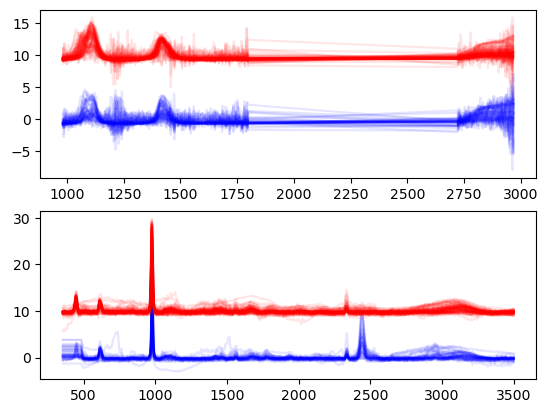

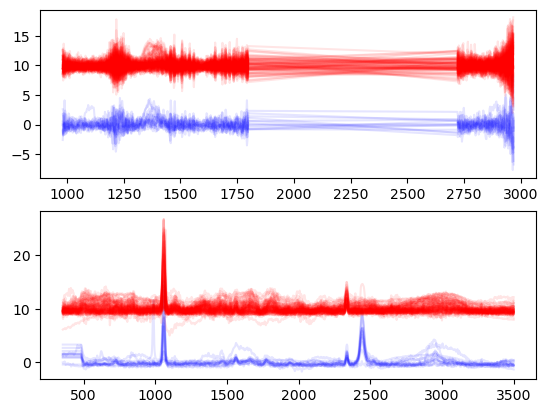

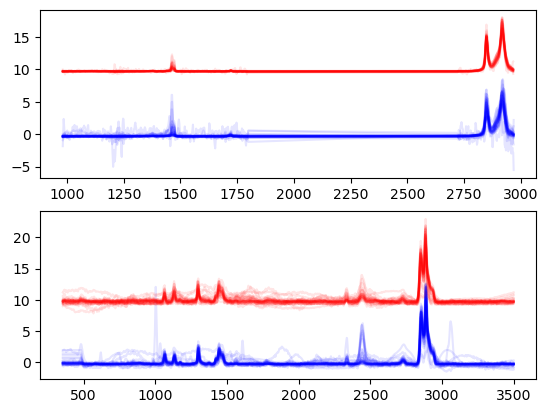

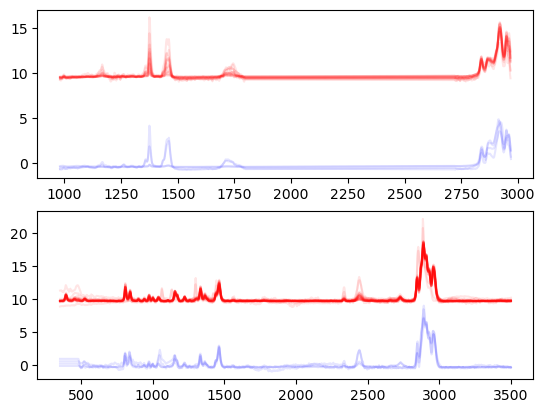

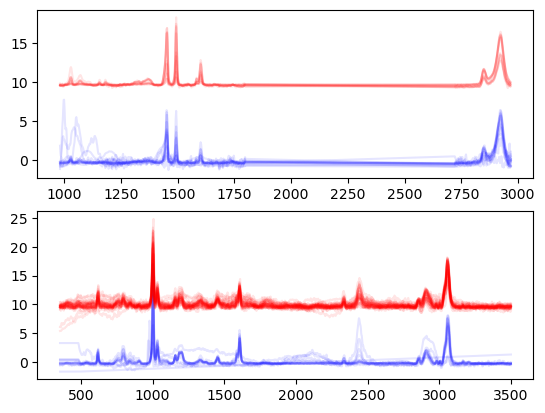

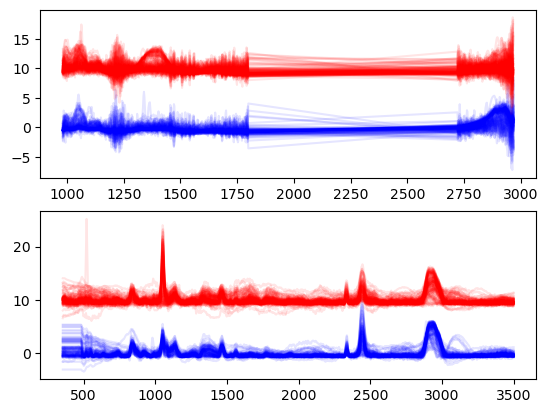

In [307]:
for p in np.unique(rebecca_data_raman['polymer']):
    fig, ax = plt.subplots(2, 1)
    print(p)
    _ = ax[1].plot(Raman_spectra_mix_std.query('polymer == @p').iloc[:,:-4].T, c='b', alpha=.1)
    _ = ax[1].plot(rebecca_data_raman.query('polymer == @p').iloc[:,:-4].T+10, c='r', alpha=.1)
    
    _ = ax[0].plot(IR_spectra_mix_std.query('polymer == @p').iloc[:,:-5].T, c='b', alpha=.1)
    _ = ax[0].plot(rebecca_data_ir.query('polymer == @p').iloc[:,:-5].T+10, c='r', alpha=.1)
    
    _ = fig.show()
    

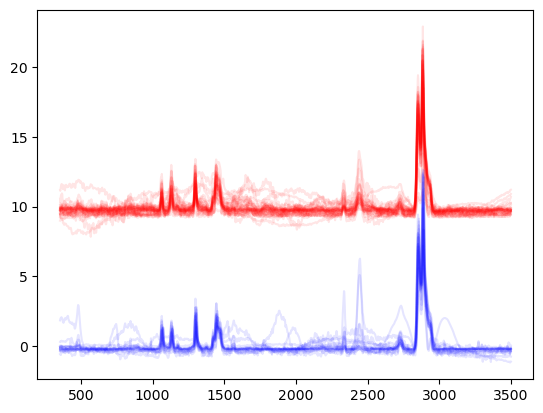

In [104]:
_ = plt.plot(rebecca_data_raman.query('polymer == "PE"').iloc[:,:-4].T+10, c='r', alpha = .1)
_ = plt.plot(Raman_spectra_mix_std.query('polymer == "PE" and id <= 128').iloc[:,:-4].T, c='b', alpha = .1)


In [105]:
IR_spectra_mix = pd.read_csv('processed_data_new/data_ir_mix_rebecca.csv')
del IR_spectra_mix['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_mix.columns = list(np.float64(IR_spectra_mix.columns[:-5])) + list(IR_spectra_mix.columns[-5:])
IR_spectra_mix_rest = IR_spectra_mix.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix = IR_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_mix['polymer']],:].reset_index(drop=True)
IR_spectra_mix.loc[IR_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'

Raman_spectra_mix = pd.read_csv('processed_data_new/data_raman_mix_rebecca_als.csv')
del Raman_spectra_mix['Unnamed: 0']
Raman_spectra_mix.columns = list(np.float64(Raman_spectra_mix.columns[:-4])) + list(Raman_spectra_mix.columns[-4:])
Raman_spectra_mix_rest = Raman_spectra_mix.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix = Raman_spectra_mix.loc[[x in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_mix['polymer']],:].reset_index(drop=True)
Raman_spectra_mix.loc[Raman_spectra_mix['polymer'] == 'LDPE','polymer'] = 'PE'


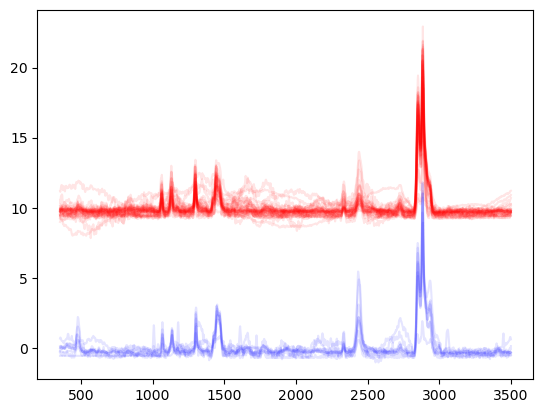

In [106]:
_ = plt.plot(rebecca_data_raman.query('polymer == "PE"').iloc[:,:-4].T+10, c='r', alpha = .1)
_ = plt.plot(Raman_spectra_mix.query('polymer == "PE" and id <= 128').iloc[:,:-4].T, c='b', alpha = .1)


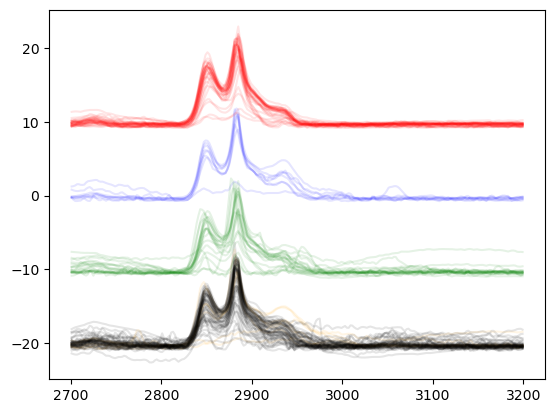

In [107]:
idx_si_peak = np.where(np.logical_and(rebecca_data_raman.columns[:-4] > 2700,
               rebecca_data_raman.columns[:-4] < 3200))[0]


_ = plt.plot(rebecca_data_raman.query('polymer == "PE"').iloc[:,:-4].iloc[:,idx_si_peak].T+10, c='r', alpha = .1)
_ = plt.plot(Raman_spectra_mix.query('polymer == "PE" and id <= 128').iloc[:,:-4].iloc[:,idx_si_peak].T, c='b', alpha = .1)

_ = plt.plot(Raman_spectra_mix.query('polymer == "PE" and id > 128 and id <=194').iloc[:,:-4].iloc[:,idx_si_peak].T-10, c='g', alpha = .1)

_ = plt.plot(Raman_spectra_mix.query('polymer == "PE" and id > 194 and id <=280').iloc[:,:-4].iloc[:,idx_si_peak].T-20, c='orange', alpha = .1)

_ = plt.plot(Raman_spectra_mix.query('polymer == "PE" and id > 280 and id <=485').iloc[:,:-4].iloc[:,idx_si_peak].T-20, c='black', alpha = .1)


NH2SO4


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_57865/1323359574.py:10: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  _ = fig.show()


NaNO3
PE
PP
PSL
sucrose


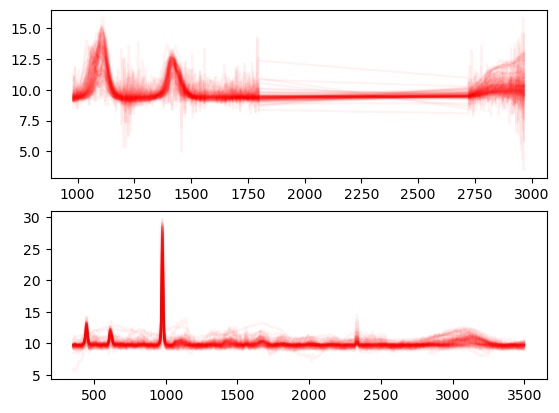

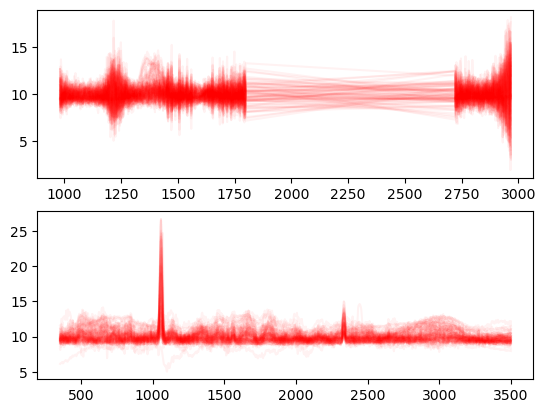

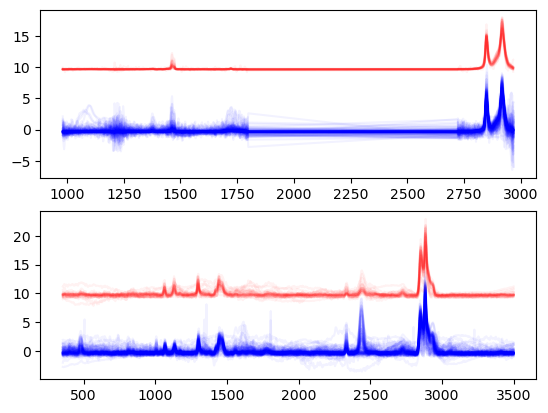

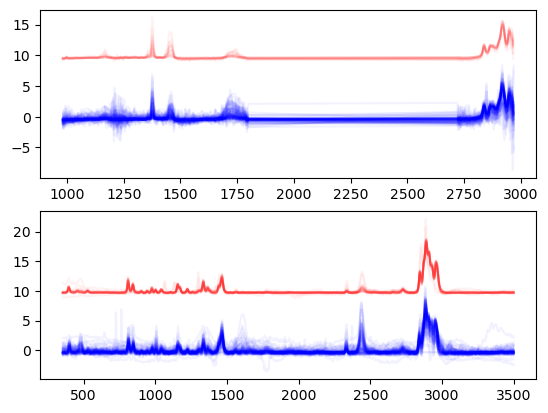

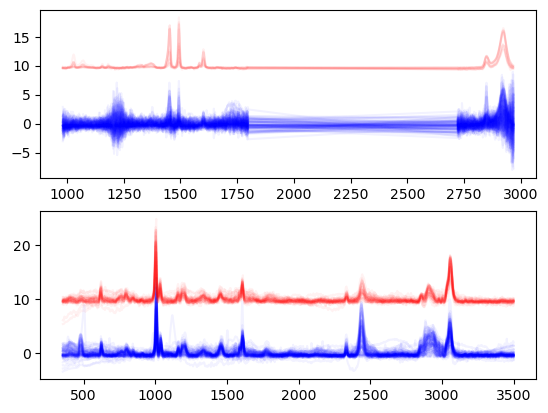

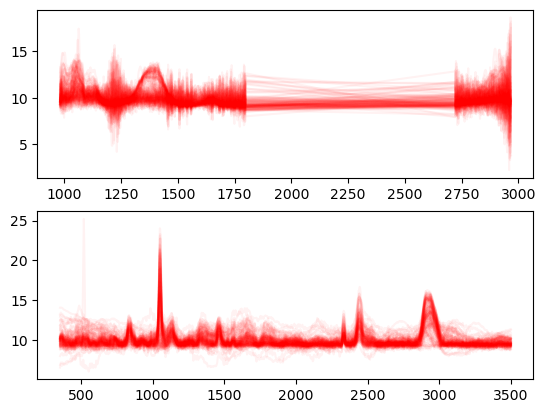

In [108]:
for p in np.unique(rebecca_data_raman['polymer']):
    fig, ax = plt.subplots(2, 1)
    print(p)
    _ = ax[1].plot(Raman_spectra_mix.query('polymer == @p').iloc[:,:-4].T, c='b', alpha=.05)
    _ = ax[1].plot(rebecca_data_raman.query('polymer == @p').iloc[:,:-4].T+10, c='r', alpha=.05)
    
    _ = ax[0].plot(IR_spectra_mix.query('polymer == @p').iloc[:,:-5].T, c='b', alpha=.05)
    _ = ax[0].plot(rebecca_data_ir.query('polymer == @p').iloc[:,:-5].T+10, c='r', alpha=.05)
    
    _ = fig.show()
    

In [109]:
IR_spectra_amb = pd.read_csv('processed_data_new/data_ir_amb_rebecca.csv')
del IR_spectra_amb['Unnamed: 0']
#non_bg = IR_spectra['background'] == 'no_background'
IR_spectra_amb.columns = list(np.float64(IR_spectra_amb.columns[:-5])) + list(IR_spectra_amb.columns[-5:])
IR_spectra_amb_rest = IR_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
IR_spectra_amb = IR_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL'] for x in IR_spectra_amb['polymer']],:].reset_index(drop=True)
IR_spectra_amb.loc[IR_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'

Raman_spectra_amb = pd.read_csv('processed_data_new/data_raman_amb_rebecca_als.csv')
del Raman_spectra_amb['Unnamed: 0']
Raman_spectra_amb.columns = list(np.float64(Raman_spectra_amb.columns[:-4])) + list(Raman_spectra_amb.columns[-4:])
Raman_spectra_amb_rest = Raman_spectra_amb.loc[[x not in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
Raman_spectra_amb = Raman_spectra_amb.loc[[x in ['LDPE', 'PP', 'PSL'] for x in Raman_spectra_amb['polymer']],:].reset_index(drop=True)
Raman_spectra_amb.loc[Raman_spectra_amb['polymer'] == 'LDPE','polymer'] = 'PE'


PE
PP


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_57865/3778397940.py:10: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.
  _ = fig.show()


PSL


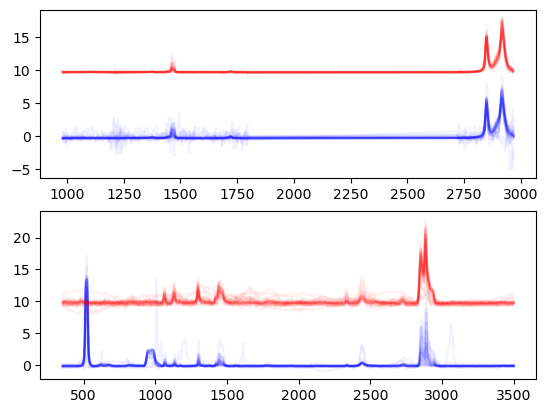

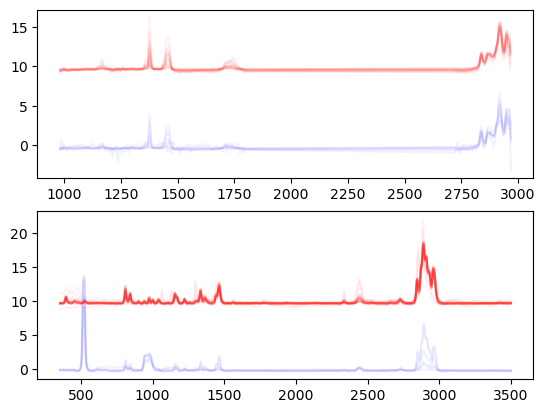

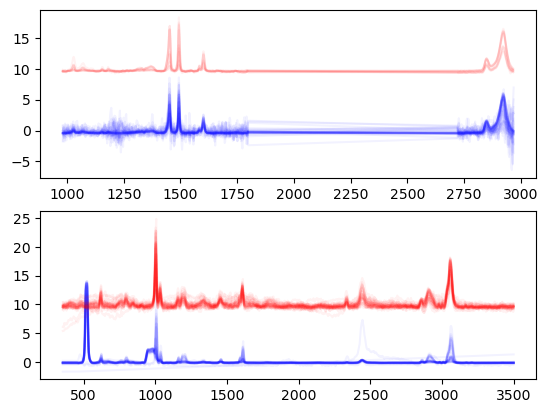

In [111]:
for p in np.unique(Raman_spectra_amb['polymer']):
    fig, ax = plt.subplots(2, 1)
    print(p)
    _ = ax[1].plot(Raman_spectra_amb.query('polymer == @p').iloc[:,:-4].T, c='b', alpha=.05)
    _ = ax[1].plot(rebecca_data_raman.query('polymer == @p').iloc[:,:-4].T+10, c='r', alpha=.05)
    
    _ = ax[0].plot(IR_spectra_amb.query('polymer == @p').iloc[:,:-5].T, c='b', alpha=.05)
    _ = ax[0].plot(rebecca_data_ir.query('polymer == @p').iloc[:,:-5].T+10, c='r', alpha=.05)
    
    _ = fig.show()
    

In [112]:
idx_si_peak = np.where(Raman_spectra_amb.columns[:-4] > 990)[0]
Raman_spectra_amb_PE_plot = Raman_spectra_amb.query('polymer == "PE" and id <= 128').iloc[:,:-4].iloc[:,idx_si_peak]#.T
Raman_spectra_amb_PE_plot = (Raman_spectra_amb_PE_plot - np.nanmean(Raman_spectra_amb_PE_plot, 1)[:,None]) /np.nanstd(Raman_spectra_amb_PE_plot, 1)[:,None]
Raman_spectra_amb_PE_plot

,991.0,993.0,995.0,997.0,999.0,1001.0,1003.0,1005.0,1007.0,1009.0,...,3481.0,3483.0,3485.0,3487.0,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0
1,2.845421,2.269926,1.647100,1.139555,0.715474,0.444754,0.207703,0.026281,-0.124767,-0.237114,...,-0.318397,-0.309152,-0.316975,-0.335071,-0.335322,-0.330993,-0.315140,-0.304140,-0.298316,-0.293516
2,10.149497,8.856752,7.402236,6.152695,5.051556,4.309342,3.665567,3.260588,2.901306,2.600250,...,-0.437100,-0.465461,-0.430650,-0.357815,-0.412195,-0.462032,-0.442790,-0.426812,-0.414315,-0.414356
4,5.269753,4.489113,3.667747,2.938140,2.274967,1.842902,1.469717,1.225382,1.004710,0.814187,...,-0.302946,-0.337587,-0.320719,-0.272848,-0.266492,-0.265821,-0.271748,-0.278717,-0.286797,-0.271542
7,15.115746,13.353599,11.365705,9.663719,8.168731,7.124668,6.203257,5.576220,5.030903,4.589705,...,-0.310890,-0.303792,-0.305922,-0.313607,-0.336804,-0.353793,-0.339367,-0.339250,-0.354388,-0.355032
9,-0.276545,-0.296780,-0.253395,-0.241606,-0.252693,-0.283680,-0.314782,-0.329582,-0.341519,-0.349807,...,-0.049922,-0.023920,-0.048007,-0.102242,-0.046759,-0.001441,-0.041100,-0.053730,-0.037544,-0.044651
14,3.091119,2.638470,2.111329,1.617051,1.146565,0.859056,0.610319,0.420227,0.268387,0.165287,...,-0.003485,0.003954,0.004747,0.001538,-0.003506,-0.006788,-0.002179,0.004661,0.013878,0.006838
16,9.856845,8.910480,7.693875,6.528024,5.398920,4.674360,4.032563,3.504072,3.054367,2.705046,...,-0.191955,-0.180071,-0.175904,-0.176381,-0.180322,-0.181615,-0.170761,-0.161423,-0.153700,-0.172313
20,3.314065,2.855859,2.285974,1.722906,1.164775,0.827917,0.539020,0.326980,0.165427,0.068202,...,-0.297159,-0.300323,-0.298721,-0.294249,-0.298174,-0.301246,-0.297509,-0.296515,-0.298445,-0.299637
23,14.930251,12.980311,10.548245,8.155520,5.791278,4.178716,2.796311,2.046695,1.386834,0.841333,...,-0.397231,-0.411175,-0.422759,-0.432922,-0.380361,-0.343407,-0.394868,-0.408036,-0.380379,-0.359121
25,4.654939,4.064430,3.337240,2.600950,1.858072,1.367471,0.942325,0.664382,0.423083,0.228475,...,-0.314983,-0.320803,-0.337116,-0.359745,-0.339962,-0.322267,-0.329933,-0.328436,-0.317170,-0.318634


In [113]:
idx_si_peak = np.where(np.logical_and(Raman_spectra_amb.columns[:-4] > 950,
                                       Raman_spectra_amb.columns[:-4] < 3200
                       ))[0]


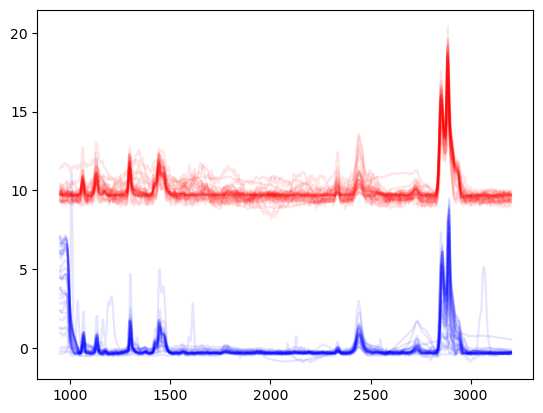

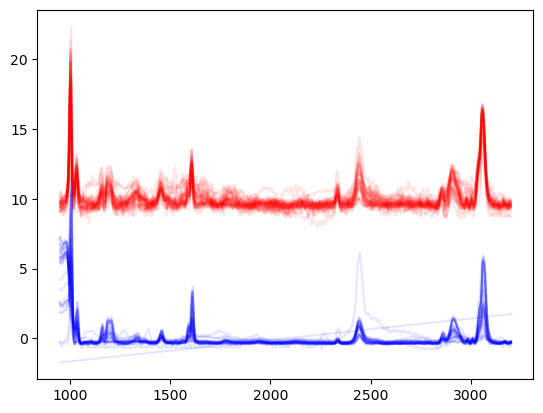

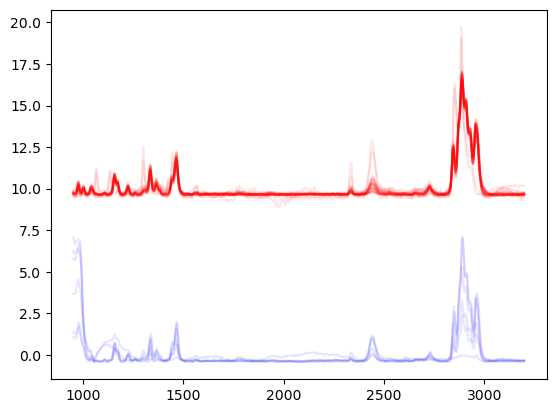

In [114]:
Raman_spectra_amb_PE_plot = Raman_spectra_amb.query('polymer == "PE"').iloc[:,:-4].iloc[:,idx_si_peak]
rebecca_data_raman_PE_plot = rebecca_data_raman.query('polymer == "PE"').iloc[:,:-4].iloc[:,idx_si_peak]

Raman_spectra_amb_PE_plot = (Raman_spectra_amb_PE_plot - np.nanmean(Raman_spectra_amb_PE_plot, 1)[:,None]) /np.nanstd(Raman_spectra_amb_PE_plot, 1)[:,None]
rebecca_data_raman_PE_plot = (rebecca_data_raman_PE_plot - np.nanmean(rebecca_data_raman_PE_plot, 1)[:,None]) /np.nanstd(rebecca_data_raman_PE_plot, 1)[:,None]

_ = plt.plot(rebecca_data_raman_PE_plot.T+10, c='r', alpha = .1)
_ = plt.plot(Raman_spectra_amb_PE_plot.T, c='b', alpha = .1)
_ = plt.show()

Raman_spectra_amb_PE_plot = Raman_spectra_amb.query('polymer == "PSL"').iloc[:,:-4].iloc[:,idx_si_peak]
rebecca_data_raman_PE_plot = rebecca_data_raman.query('polymer == "PSL"').iloc[:,:-4].iloc[:,idx_si_peak]

Raman_spectra_amb_PE_plot = (Raman_spectra_amb_PE_plot - np.nanmean(Raman_spectra_amb_PE_plot, 1)[:,None]) /np.nanstd(Raman_spectra_amb_PE_plot, 1)[:,None]
rebecca_data_raman_PE_plot = (rebecca_data_raman_PE_plot - np.nanmean(rebecca_data_raman_PE_plot, 1)[:,None]) /np.nanstd(rebecca_data_raman_PE_plot, 1)[:,None]

_ = plt.plot(rebecca_data_raman_PE_plot.T+10, c='r', alpha = .1)
_ = plt.plot(Raman_spectra_amb_PE_plot.T, c='b', alpha = .1)
_ = plt.show()

Raman_spectra_amb_PE_plot = Raman_spectra_amb.query('polymer == "PP"').iloc[:,:-4].iloc[:,idx_si_peak]
rebecca_data_raman_PE_plot = rebecca_data_raman.query('polymer == "PP"').iloc[:,:-4].iloc[:,idx_si_peak]

Raman_spectra_amb_PE_plot = (Raman_spectra_amb_PE_plot - np.nanmean(Raman_spectra_amb_PE_plot, 1)[:,None]) /np.nanstd(Raman_spectra_amb_PE_plot, 1)[:,None]
rebecca_data_raman_PE_plot = (rebecca_data_raman_PE_plot - np.nanmean(rebecca_data_raman_PE_plot, 1)[:,None]) /np.nanstd(rebecca_data_raman_PE_plot, 1)[:,None]

_ = plt.plot(rebecca_data_raman_PE_plot.T+10, c='r', alpha = .1)
_ = plt.plot(Raman_spectra_amb_PE_plot.T, c='b', alpha = .1)


In [115]:
idx_si_peak = np.where(Raman_spectra_amb.columns[:-4] > 1040)[0]


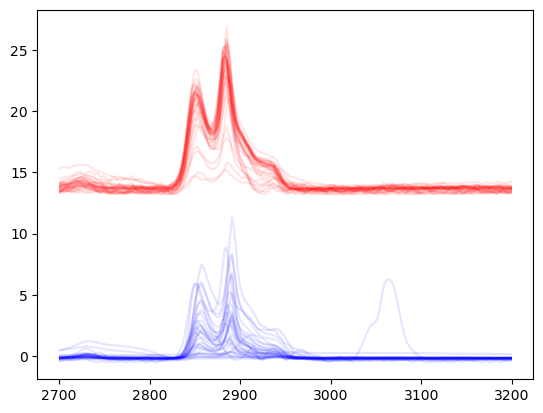

In [116]:
idx_si_peak = np.where(np.logical_and(Raman_spectra_amb.columns[:-4] > 2700,
               Raman_spectra_amb.columns[:-4] < 3200))[0]

p = 'PE'
_ = plt.plot(Raman_spectra_amb.query('polymer == @p').iloc[:,:-4].iloc[:,idx_si_peak].T, c='b', alpha=.1)
_ = plt.plot(rebecca_data_raman.query('polymer == @p').iloc[:,:-4].iloc[:,idx_si_peak].T+14, c='r', alpha=.1)

#_ = plt.legend()

In [93]:
def process_data(rebecca_data_ir, rebecca_data_raman, IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 
    
    wn_rb = np.array(rebecca_data_ir.columns[:-4])
    idx_rb = list(np.logical_or(np.logical_and(wn_rb > 980, wn_rb < 1800),
                           np.logical_and(wn_rb > 2720, wn_rb < 2950)
                          ) ) + [False]*4
    
    wn_rb_r = np.array(rebecca_data_raman.columns[:-4])
    idx_rb_r = list(np.logical_and(wn_rb_r > range_r[0], wn_rb_r < range_r[1])) + [False]*4


    wn_rb_amb = np.array(IR_spectra.columns[:-5])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*5
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4
    
    x_train_ir = rebecca_data_ir.iloc[:,idx_rb].to_numpy()
    x_train_ir = (x_train_ir - x_train_ir.mean(1)[:, None]) / x_train_ir.std(1)[:, None]
    y_train_ir = rebecca_data_ir.iloc[:,-2]

    x_train_raman = rebecca_data_raman.iloc[:,idx_rb_r].to_numpy()
    x_train_raman = (x_train_raman - x_train_raman.mean(1)[:, None]) / x_train_raman.std(1)[:, None]
    y_train_raman = rebecca_data_raman.iloc[:,-2]

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]
    y_test = IR_spectra.iloc[:,-3]
    
    idx_test = np.sum(np.isnan(x_raman), axis=1) == 0
    
    x_ir = x_ir[idx_test,:]
    x_raman = x_raman[idx_test,:]
    y_raman = y_test[idx_test]
    y_ir = y_test[idx_test]
    
    #y_test[y_test == 'LDPE'] = 'PE'
    
    poly_list = list(np.unique(y_train_raman))
    label_table = pd.DataFrame({'label':np.arange(len(poly_list)), 'polymer':poly_list})
    label_train_Raman = np.array(pd.DataFrame(y_train_raman).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    label_train_IR = np.array(pd.DataFrame(y_train_ir).merge(label_table, left_on="polymer", right_on="polymer")['label'])
    
    label_ir = np.array(pd.DataFrame(y_ir).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    label_raman = np.array(pd.DataFrame(y_raman).merge(label_table, how='left', left_on="polymer", right_on="polymer")['label'])
    
    return x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table


In [7]:
def process_data_2(IR_spectra, Raman_spectra, range_r=[550, 3500]):
    
    #range_r = [550, 3500] 


    wn_rb_amb = np.array(IR_spectra.columns[:-5])
    idx_rb_amb = list(np.logical_or(np.logical_and(wn_rb_amb > 980, wn_rb_amb < 1800),
                           np.logical_and(wn_rb_amb > 2720, wn_rb_amb < 2950) #2993.64990234375-10
                          ) ) + [False]*5
    
    wn_rb_amb_r = np.array(Raman_spectra.columns[:-4])
    idx_rb_amb_r = list(np.logical_and(wn_rb_amb_r > range_r[0], wn_rb_amb_r < range_r[1])) + [False]*4

    x_ir = IR_spectra.iloc[:,idx_rb_amb].to_numpy()
    x_ir = (x_ir - x_ir.mean(1)[:, None]) / x_ir.std(1)[:, None]    

    x_raman = Raman_spectra.iloc[:,idx_rb_amb_r].to_numpy()
    x_raman = (x_raman - x_raman.mean(1)[:, None]) / x_raman.std(1)[:, None]

    y_test = IR_spectra.iloc[:,-3]
    #y_test[y_test == 'LDPE'] = 'PE'
    
    return x_ir, x_raman, y_test

In [8]:
def experiment(score_list, label_ir, alphas, N_sim, seed=0):
    df_res_lis = []
    df_res_sd_lis = []
    df_res_cov_lis = []
    df_res_cov_sd_lis = []

    for alpha in tqdm(alphas):
        set_size = defaultdict(list)
        set_size_all = defaultdict(list)
        zero_sets = defaultdict(list)
        cov = defaultdict(list)
        cov_cal = defaultdict(list)
        set_size_by_label_hqi = defaultdict(list)
        K = 2
        U_list = gen_u(K, seed=0)
        for l in range(N_sim):
            seed = seed + l

            #score_list, y_train, y_test, top_views = simulate_s_2(N, d, d_v, L, scale, K, N_train, seed)
            #top_views = np.array(acc_list)
            quant_smx_list = []
            rest_smx_list = []
            cal_smx_list = []
            val_smx_list = []


            for i in range(K):

                quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
                #print(quant_smx.shape, rest_smx.shape)
                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
                #print(cal_smx.shape, val_smx.shape)

                quant_smx_list.append(quant_smx)
                rest_smx_list.append(rest_smx)
                cal_smx_list.append(cal_smx)
                val_smx_list.append(val_smx)

            n = cal_labels.shape[0]

            for j in range(1,K):

                prediction_sets, empirical_coverage = mvcp_2(quant_smx_list[:(j+1)],
                                                             quant_labels,
                                                             cal_smx_list[:(j+1)], 
                                                             cal_labels, 
                                                             val_smx_list[:(j+1)], 
                                                             alpha, 
                                                             val_labels, 
                                                             U=U_list[0])

                #prediction_sets, empirical_coverage = mvcp(quant_smx_list[0],
                #                                           quant_smx_list[1],
                #                                             quant_labels,
                #                                             cal_smx_list[0], 
                #                                           val_smx_list[0], 
                #                                          cal_smx_list[1], 
                #                                          val_smx_list[1], 
                #                                          cal_labels, 
                #                                            alpha, 
                #                                            val_labels)
                


                set_size['mvcp'+str(j+1)].append(
                    prediction_sets.sum(1).mean()
                )
                set_size_all['mvcp'+str(j+1)].append(
                    prediction_sets.sum(1)
                )
                zero_sets['mvcp'+str(j+1)].append(
                    np.mean(prediction_sets.sum(1) == 0)
                )
                cov['mvcp'+str(j+1)].append(
                    empirical_coverage
                )

                set_size_by_label_hqi['mvcp'+str(j+1)].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

                s_u = rest_smx_list[:(j+1)][0]
                #print(top_views[:(j+1)])
                #print(np.argmax(top_views[:(j+1)]))

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['view_IR'+str(j+1)].append(prediction_sets.sum(1).mean())

                set_size_all['view_IR'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

                zero_sets['view_IR'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['view_IR'+str(j+1)].append(empirical_coverage)

                set_size_by_label_hqi['view_IR'+str(j+1)].append(
                    pd.DataFrame({'label':val_labels, 
                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
                )

                s_u = rest_smx_list[:(j+1)][1]
                #print(top_views[:(j+1)])
                #print(np.argmax(top_views[:(j+1)]))

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())

                set_size_all['view_Raman'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

                zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['view_Raman'+str(j+1)].append(empirical_coverage)

                s_u = np.sum(rest_smx_list[:(j+1)], 0)

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['sum'+str(j+1)].append(prediction_sets.sum(1).mean())
                zero_sets['sum'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['sum'+str(j+1)].append(empirical_coverage)

                s_u = np.power(rest_smx_list[:(j+1)],2).sum(0)

                cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                n = cal_smx.shape[0]
                (prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                set_size['norm'+str(j+1)].append(prediction_sets.sum(1).mean())
                zero_sets['norm'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
                cov['norm'+str(j+1)].append(empirical_coverage)

                #s_u = s_pre_fused[j-1][~idx_quant,:]

                #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(s_u, rest_labels, cal_prop=0.8, seed=seed)
                #n = cal_smx.shape[0]
                #(prediction_sets, empirical_coverage), qhat = conform_prediction(cal_smx, val_smx, cal_labels, n, alpha, val_labels, cond=0)
                #set_size['pre_fused'+str(j+1)].append(prediction_sets.sum(1).mean())
                #cov['pre_fused'+str(j+1)].append(empirical_coverage)

        df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(set_size).std()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_sd_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).mean()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_lis.append(df_res)

        df_res = pd.DataFrame(pd.DataFrame(cov).std()).reset_index()
        df_res['cp'] = [s[:-1] for s in df_res['index']]
        df_res['M'] = [s[-1] for s in df_res['index']]
        del df_res['index']
        df_res = df_res.pivot(index='M', columns='cp', values=0).loc[:,['view_IR','view_Raman', 'mvcp']]
        df_res = df_res.reset_index(drop=True)

        df_res_cov_sd_lis.append(df_res)

    return df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis

In [9]:
alphas = np.arange(.05,.4,.05)
N_sim = 10

# Ambient

In [146]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     IR_spectra_amb, 
                                                                                                     Raman_spectra_amb,
                                                                                                     range_r=[990, 3200])

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_amb_rest, Raman_spectra_amb_rest, range_r=[990, 3200])


In [147]:
Raman_spectra_amb.iloc[18:19,:]

,355.0,357.0,359.0,361.0,363.0,365.0,367.0,369.0,371.0,373.0,...,3489.0,3491.0,3493.0,3495.0,3497.0,3499.0,map_x,map_y,polymer,id
18,-1.730363,-1.730363,-1.730363,-1.730363,-1.730363,-1.730363,-1.730363,-1.730363,-1.730363,-1.730363,...,1.265316,1.26729,1.269264,1.271239,1.273213,1.275187,0,0,PSL,61


In [155]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman] # + np.random.rand(smx_all_IR.shape[0], smx_all_IR.shape[1])/3

In [156]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [154]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_raman)

(0.9444444444444444, 0.8194444444444444)

In [117]:
alpha = .5
seed = 1
set_size = defaultdict(list)
set_size_all = defaultdict(list)
zero_sets = defaultdict(list)
cov = defaultdict(list)
cov_cal = defaultdict(list)
set_size_by_label_hqi = defaultdict(list)
K = 2
U_list = gen_u(K, seed=0)
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
for i in range(K):
    quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
                #print(quant_smx.shape, rest_smx.shape)
    #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
                #print(cal_smx.shape, val_smx.shape)

    quant_smx_list.append(quant_smx)
    rest_smx_list.append(rest_smx)
    #cal_smx_list.append(cal_smx)
    #val_smx_list.append(val_smx)

    #n = cal_labels.shape[0]

for j in range(1,K):

    prediction_sets_mvcp = mvcp_2(quant_smx_list[:(j+1)],
                                                             quant_labels,
                                                             rest_smx_list[:(j+1)], 
                                                             rest_labels, 
                                                             score_list_rest[:(j+1)], 
                                                             alpha, 
                                                             val_labels=None)



    set_size['mvcp'+str(j+1)].append(
                        prediction_sets.sum(1).mean()
                    )
    set_size_all['mvcp'+str(j+1)].append(
                        prediction_sets.sum(1)
                    )
    zero_sets['mvcp'+str(j+1)].append(
                        np.mean(prediction_sets.sum(1) == 0)
                    )
    #cov['mvcp'+str(j+1)].append(
    #                    empirical_coverage
    #                )

    #set_size_by_label_hqi['mvcp'+str(j+1)].append(
    #                    pd.DataFrame({'label':val_labels, 
    #                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    #                )
    
    
    #s_u = rest_smx_list[:(j+1)][0]
    s_u = score_list[0]
    n = s_u.shape[0]
    prediction_sets, qhat = conform_prediction(s_u, score_list_rest[0], label_ir, n, alpha, val_labels=None, cond=0)
    set_size['view_IR'+str(j+1)].append(prediction_sets.sum(1).mean())

    set_size_all['view_IR'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

    zero_sets['view_IR'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
    
    #s_u = rest_smx_list[:(j+1)][1]
    #n = s_u.shape[0]
    #prediction_sets, qhat = conform_prediction(s_u, score_list_rest[1], rest_labels, n, alpha, val_labels=None, cond=0)
    #set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())

    #set_size_all['view_Raman'+str(j+1)].append(
    #                prediction_sets.sum(1)
    #            )

    #zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))

NameError: name 'prediction_sets' is not defined

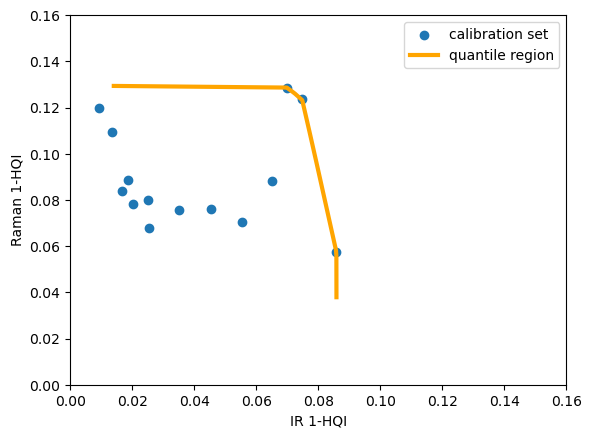

In [95]:
alpha = .1
beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels)
#U = np.array([u/np.linalg.norm(u) for u in U])
n = rest_smx_list[0].shape[0]
t = np.max([project_u_mv(rest_smx_list, U[th,:])[0][np.arange(n),rest_labels]/q for th, q in enumerate(q_array)], 0)


cal_x = smx_all_IR[np.arange(label_ir.shape[0]),label_ir]
cal_y = smx_all_Raman[np.arange(label_ir.shape[0]),label_ir]

#plt.scatter(cal_x[cal_x<.2],
#            cal_y[cal_x<.2], 
#            label='calibration set')

plt.scatter(quant_smx_list[0][np.arange(quant_labels.shape[0]),quant_labels],
            quant_smx_list[1][np.arange(quant_labels.shape[0]),quant_labels], 
            label='calibration set')

#plt.scatter(smx_all_IR_rest.min(1),
#            smx_all_Raman_rest.min(1))

#plt.scatter(U[:,0],
#            U[:,1])

#plt.scatter(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t,
#            rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t, 
#            label='quantile region')

idx_quant_reg = np.argsort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_x = np.sort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_y = (rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t)[idx_quant_reg]

plt.plot(quant_reg_x,
         quant_reg_y, 
         label='quantile region',
         c='orange',
         linewidth=3.0
     )

plt.xlabel("IR 1-HQI")
plt.ylabel("Raman 1-HQI")
plt.xlim(0.0,.16)
plt.ylim(0.0,.16)

plt.legend()

(array([14., 14., 24., 10.,  2.,  5.,  1.,  0.,  1.,  1.]),
 array([0.02611354, 0.04554149, 0.06496943, 0.08439738, 0.10382533,
        0.12325328, 0.14268123, 0.16210918, 0.18153713, 0.20096508,
        0.22039303]),
 <BarContainer object of 10 artists>)

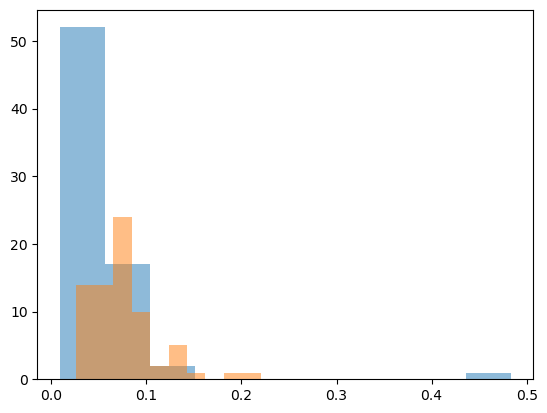

In [96]:
cal_x = smx_all_IR[np.arange(label_ir.shape[0]),label_ir]
cal_y = smx_all_Raman[np.arange(label_ir.shape[0]),label_ir]

plt.hist(cal_x, alpha=.5)
plt.hist(cal_y, alpha=.5)

In [128]:
df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis = experiment(score_list, label_ir, alphas, N_sim, seed=0)


100%|█████████████████████████████████████████████| 7/7 [00:02<00:00,  2.56it/s]


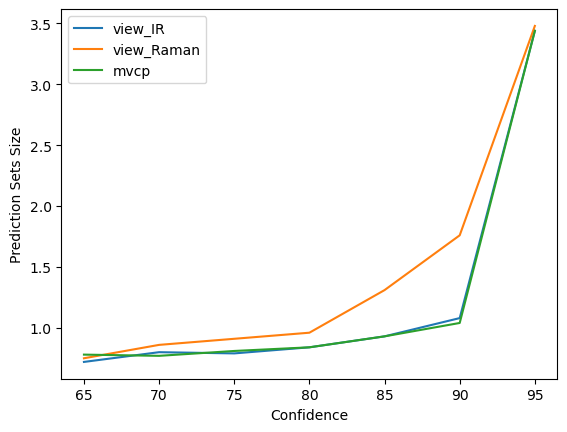

In [74]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

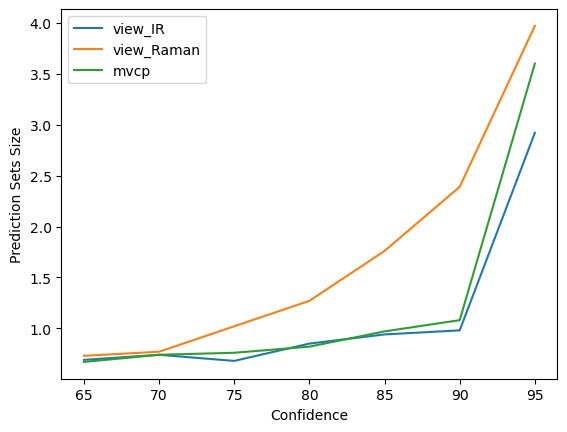

In [129]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [75]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,99.0,98.0,98.0,95.0
0,96.0,91.0,93.0,90.0
0,91.0,86.0,89.0,85.0
0,83.0,81.0,83.0,80.0
0,79.0,82.0,81.0,75.0
0,79.0,70.0,76.0,70.0
0,70.0,67.0,77.0,65.0


In [130]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,99.0,98.0,98.0,95.0
0,95.0,93.0,94.0,90.0
0,93.0,90.0,91.0,85.0
0,83.0,82.0,81.0,80.0
0,68.0,84.0,76.0,75.0
0,73.0,68.0,73.0,70.0
0,68.0,65.0,65.0,65.0


# Mix

In [131]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     IR_spectra_mix, 
                                                                                                     Raman_spectra_mix)

#x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_rest, Raman_spectra_mix_rest)

In [132]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

In [35]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [133]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_ir)

(0.7654723127035831, 0.7296416938110749)

In [37]:
alpha = .2
seed = 0
set_size = defaultdict(list)
set_size_all = defaultdict(list)
zero_sets = defaultdict(list)
cov = defaultdict(list)
cov_cal = defaultdict(list)
set_size_by_label_hqi = defaultdict(list)
K = 2
U_list = gen_u(K, seed=0)
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
for i in range(K):
    quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
                #print(quant_smx.shape, rest_smx.shape)
    #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
                #print(cal_smx.shape, val_smx.shape)

    quant_smx_list.append(quant_smx)
    rest_smx_list.append(rest_smx)
    #cal_smx_list.append(cal_smx)
    #val_smx_list.append(val_smx)

    #n = cal_labels.shape[0]

for j in range(1,K):

    prediction_sets_mvcp = mvcp_2(quant_smx_list[:(j+1)],
                                                             quant_labels,
                                                             rest_smx_list[:(j+1)], 
                                                             rest_labels, 
                                                             score_list_rest[:(j+1)], 
                                                             alpha, 
                                                             val_labels=None)



    set_size['mvcp'+str(j+1)].append(
                        prediction_sets.sum(1).mean()
                    )
    set_size_all['mvcp'+str(j+1)].append(
                        prediction_sets.sum(1)
                    )
    zero_sets['mvcp'+str(j+1)].append(
                        np.mean(prediction_sets.sum(1) == 0)
                    )
    #cov['mvcp'+str(j+1)].append(
    #                    empirical_coverage
    #                )

    #set_size_by_label_hqi['mvcp'+str(j+1)].append(
    #                    pd.DataFrame({'label':val_labels, 
    #                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    #                )
    
    
    #s_u = rest_smx_list[:(j+1)][0]
    s_u = score_list[0]
    n = s_u.shape[0]
    prediction_sets, qhat = conform_prediction(s_u, score_list_rest[0], label_ir, n, alpha, val_labels=None, cond=0)
    set_size['view_IR'+str(j+1)].append(prediction_sets.sum(1).mean())

    set_size_all['view_IR'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

    zero_sets['view_IR'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))
    
    #s_u = rest_smx_list[:(j+1)][1]
    #n = s_u.shape[0]
    #prediction_sets, qhat = conform_prediction(s_u, score_list_rest[1], rest_labels, n, alpha, val_labels=None, cond=0)
    #set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())

    #set_size_all['view_Raman'+str(j+1)].append(
    #                prediction_sets.sum(1)
    #            )

    #zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))

NameError: name 'prediction_sets' is not defined

In [889]:
beta

0.1

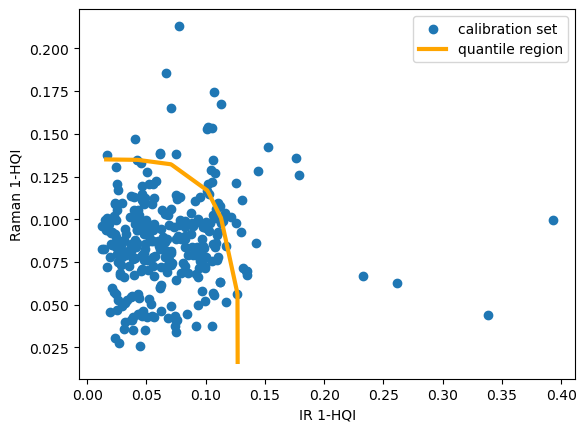

In [890]:
alpha = .1
beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels)
#U = np.array([u/np.linalg.norm(u) for u in U])
n = rest_smx_list[0].shape[0]
t = np.max([project_u_mv(rest_smx_list, U[th,:])[0][np.arange(n),rest_labels]/q for th, q in enumerate(q_array)], 0)



plt.scatter(smx_all_IR[np.arange(label_ir.shape[0]),label_ir],
            smx_all_Raman[np.arange(label_ir.shape[0]),label_ir], 
            label='calibration set')

#plt.scatter(smx_all_IR_rest.min(1),
#            smx_all_Raman_rest.min(1))

#plt.scatter(U[:,0],
#            U[:,1])

#plt.scatter(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t,
#            rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t, 
#            label='quantile region')

idx_quant_reg = np.argsort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_x = np.sort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_y = (rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t)[idx_quant_reg]

plt.plot(quant_reg_x,
         quant_reg_y, 
         label='quantile region',
         c='orange',
         linewidth=3.0
     )

plt.xlabel("IR 1-HQI")
plt.ylabel("Raman 1-HQI")

plt.legend()

(array([ 26.,  31.,  70., 108.,  40.,  21.,   6.,   3.,   1.,   1.]),
 array([0.02606358, 0.04477366, 0.06348375, 0.08219383, 0.10090392,
        0.119614  , 0.13832408, 0.15703417, 0.17574425, 0.19445433,
        0.21316442]),
 <BarContainer object of 10 artists>)

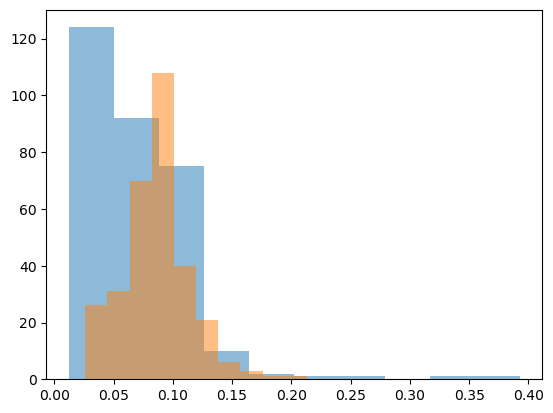

In [892]:
plt.hist(smx_all_IR[np.arange(label_ir.shape[0]),label_ir], alpha=.5)
plt.hist(smx_all_Raman[np.arange(label_ir.shape[0]),label_ir], alpha=.5)

In [770]:
[(np.unique(['PE', 'PP', 'PSL'])[x],y) for x,y in zip(prediction_sets, y_ir_rest)]

IndexError: boolean index did not match indexed array along dimension 0; dimension is 3 but corresponding boolean dimension is 6

In [134]:
df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis = experiment(score_list, label_ir, alphas, N_sim, seed=0)

100%|█████████████████████████████████████████████| 7/7 [00:07<00:00,  1.02s/it]


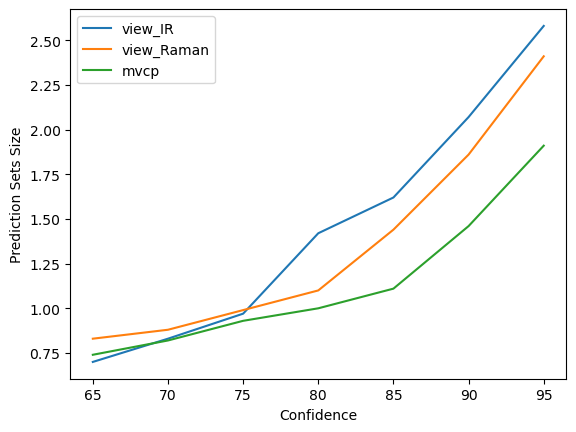

In [82]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

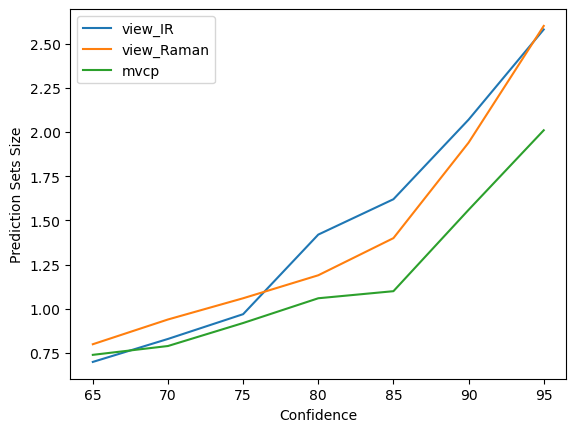

In [135]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [83]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,96.0,97.0,96.0,95.0
0,90.0,92.0,92.0,90.0
0,86.0,86.0,87.0,85.0
0,82.0,80.0,80.0,80.0
0,75.0,76.0,78.0,75.0
0,74.0,72.0,74.0,70.0
0,67.0,69.0,71.0,65.0


In [136]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,96.0,97.0,95.0,95.0
0,90.0,93.0,92.0,90.0
0,86.0,86.0,87.0,85.0
0,82.0,80.0,82.0,80.0
0,75.0,73.0,76.0,75.0
0,74.0,72.0,71.0,70.0
0,67.0,67.0,69.0,65.0


# Mix-Std

In [95]:
x_train_ir, x_train_raman, label_train_IR, label_train_Raman, x_ir, x_raman, label_ir, label_raman, label_table = process_data(rebecca_data_ir, 
                                                                                                     rebecca_data_raman, 
                                                                                                     IR_spectra_mix_std, 
                                                                                                     Raman_spectra_mix_std)

x_ir_rest, x_raman_rest, y_ir_rest = process_data_2(IR_spectra_mix_std_rest, Raman_spectra_mix_std_rest)


In [96]:
label_table

,label,polymer
0,0,NH2SO4
1,1,NaNO3
2,2,PE
3,3,PP
4,4,PSL
5,5,sucrose


In [66]:
Raman_spectra_mix_std_rest['polymer']

0      LOW SIGNAL
1      LOW SIGNAL
2      LOW SIGNAL
3      LOW SIGNAL
4      LOW SIGNAL
          ...    
200      UNSORTED
201      UNSORTED
202      UNSORTED
203      UNSORTED
204      UNSORTED
Name: polymer, Length: 205, dtype: object

In [67]:
np.unique(Raman_spectra_mix_std['polymer'])

array(['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'], dtype=object)

In [68]:
np.unique(Raman_spectra_mix_std_rest['polymer'])

array(['LOW SIGNAL', 'MIXTURE', 'UNSORTED'], dtype=object)

In [69]:
IR_spectra_mix_std_rest

,981.0,983.0,985.0,987.0,989.0,991.0,993.0,995.0,997.0,999.0,...,2961.0,2963.0,2965.0,2967.0,2969.0,map_x,map_y,polymer,id,background
0,-0.438056,0.933417,2.150888,2.177525,0.860700,0.452132,-0.315118,-1.185153,-0.967110,-0.651419,...,-8.767647,-5.406181,-1.714433,1.018770,2.725846,0,0,LOW SIGNAL,3,background
1,1.638889,0.455108,-0.441436,-0.560524,-1.166359,-1.748550,-1.613215,-1.766743,-1.025346,0.141626,...,2.818375,-0.981516,-1.059169,1.408004,2.597168,0,0,LOW SIGNAL,4,no_background
2,0.205335,1.241631,0.875970,-0.050083,-0.290827,0.486683,0.731929,0.275573,0.824066,0.533222,...,-4.550883,-4.196163,0.931492,0.827264,-0.205617,0,0,LOW SIGNAL,5,background
3,-0.664309,-0.239300,0.014566,-0.208587,-0.046960,0.170434,-0.076865,-0.973157,-0.754876,0.120356,...,-1.512306,-2.241481,-6.110776,-5.434061,-4.061654,0,0,LOW SIGNAL,9,no_background
4,0.458646,0.371627,-0.220833,-0.842041,0.086381,0.212940,0.388129,1.443957,1.272194,0.349790,...,-0.588356,-3.162504,-4.946962,-3.286108,3.421792,0,0,LOW SIGNAL,13,no_background
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,0.540456,0.861081,0.991776,0.992295,1.156026,1.460844,1.659911,1.771708,1.833177,1.816523,...,-0.337924,-0.306136,-0.376574,-0.375876,-0.446557,0,0,UNSORTED,385,no_background
201,-0.047173,0.174531,0.363904,0.489940,0.604610,0.754936,0.909291,1.006005,1.027947,1.001221,...,0.968824,0.914259,0.845367,0.830028,0.766011,0,0,UNSORTED,389,no_background
202,-0.413723,-0.348733,-0.229346,-0.094219,-0.024936,-0.067491,-0.089435,-0.070198,0.043856,0.203410,...,0.278251,0.175863,0.038327,-0.113022,-0.136827,0,0,UNSORTED,390,no_background
203,-0.726814,-0.545082,0.767066,1.174589,2.338367,2.630447,0.976126,0.843917,0.305564,-0.488433,...,2.420623,1.407416,0.094167,3.591330,6.116797,0,0,UNSORTED,402,background


In [70]:
smx_all_IR = 1-np.power(smx_nn(x_train_ir, x_ir, label_train_IR),1)
smx_all_Raman = 1-np.power(smx_nn(x_train_raman, x_raman, label_train_Raman),1)
score_list = [smx_all_IR, smx_all_Raman]

In [71]:
smx_all_IR_rest = 1-np.power(smx_nn(x_train_ir, x_ir_rest, label_train_IR),1)
smx_all_Raman_rest = 1-np.power(smx_nn(x_train_raman, x_raman_rest, label_train_Raman),1)
score_list_rest = [smx_all_IR_rest, smx_all_Raman_rest]

In [72]:
label_ir

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4,
       3, 3, 3, 3])

In [73]:
np.nanmean(np.argmin(score_list[0], 1) == label_ir), np.nanmean(np.argmin(score_list[1], 1) == label_ir)

(0.84375, 0.8705357142857143)

(array([ 1.21366663,  1.21366663,  1.21366663,  3.6409999 ,  1.82049995,
         6.06833317,  6.06833317,  9.70933307, 13.95716628, 79.49516448]),
 array([0.0147764 , 0.02281493, 0.03085346, 0.03889199, 0.04693052,
        0.05496905, 0.06300758, 0.07104612, 0.07908465, 0.08712318,
        0.09516171]),
 <BarContainer object of 10 artists>)

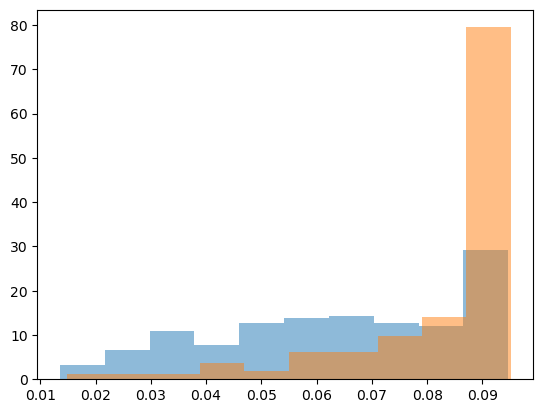

In [74]:
#
plt.hist(score_list[0].min(1), density=True, alpha=.5)
plt.hist(score_list_rest[0].min(1), density=True, alpha=.5)

In [75]:
df_res_lis, df_res_sd_lis, df_res_cov_lis, df_res_cov_sd_lis = experiment(score_list, label_ir, alphas, N_sim, seed=0)


100%|█████████████████████████████████████████████| 7/7 [00:05<00:00,  1.35it/s]


In [167]:
df_res_sd_lis

[cp   view_IR  view_Raman      mvcp
 0   0.261498    0.255327  0.196528,
 cp   view_IR  view_Raman      mvcp
 0   0.111458    0.057078  0.038064,
 cp   view_IR  view_Raman      mvcp
 0   0.041923    0.032208  0.061419,
 cp   view_IR  view_Raman      mvcp
 0   0.043921    0.043033  0.061767,
 cp   view_IR  view_Raman      mvcp
 0   0.112491    0.081828  0.101472,
 cp   view_IR  view_Raman      mvcp
 0   0.069599    0.067789  0.071722,
 cp   view_IR  view_Raman      mvcp
 0   0.071961    0.076578  0.087106]

In [345]:
pd.concat(df_res_sd_lis, axis=0)

cp,view_IR,view_Raman,mvcp
0,0.261498,0.255327,0.196528
0,0.111458,0.057078,0.038064
0,0.041923,0.032208,0.061419
0,0.043921,0.043033,0.061767
0,0.112491,0.081828,0.101472
0,0.069599,0.067789,0.071722
0,0.071961,0.076578,0.087106


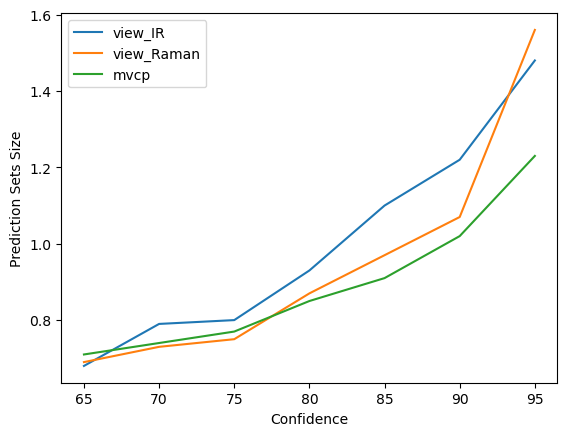

In [52]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

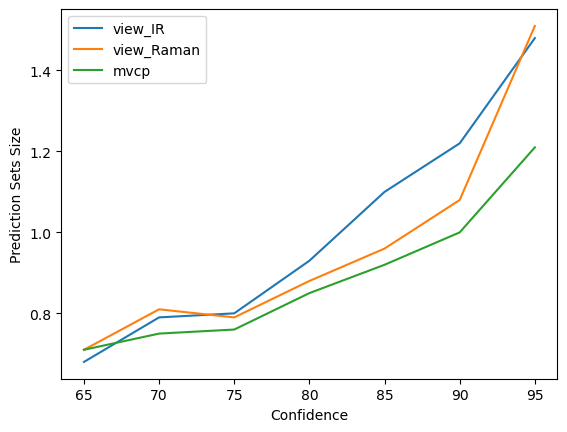

In [18]:
df_res_all = pd.concat(df_res_lis, axis=0)
df_res_all['confidence'] = (1-alphas)*100
_ = plt.plot(np.round(df_res_all, 2).set_index('confidence'))
_ = plt.legend(['view_IR', 'view_Raman', 'mvcp'])
_ = plt.xlabel("Confidence")
_ = plt.ylabel("Prediction Sets Size")
#_ = plt.ylim(0,6)

In [275]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,96.0,95.0,95.0,95.0
0,92.0,92.0,92.0,90.0
0,90.0,84.0,86.0,85.0
0,85.0,81.0,82.0,80.0
0,75.0,73.0,74.0,75.0
0,75.0,77.0,73.0,70.0
0,67.0,68.0,69.0,65.0


In [347]:
df_res_all = pd.concat(df_res_cov_lis, axis=0)*100
df_res_all['confidence'] = (1-alphas)*100
np.round(df_res_all)

cp,view_IR,view_Raman,mvcp,confidence
0,96.0,95.0,95.0,95.0
0,92.0,92.0,92.0,90.0
0,90.0,84.0,86.0,85.0
0,85.0,81.0,82.0,80.0
0,75.0,73.0,74.0,75.0
0,75.0,77.0,73.0,70.0
0,67.0,68.0,69.0,65.0


In [31]:
(score_list_rest[0].shape,
score_list_rest[1].shape)

((205, 6), (205, 6))

In [123]:
alpha = .05
seed = 0
set_size = defaultdict(list)
set_size_all = defaultdict(list)
zero_sets = defaultdict(list)
cov = defaultdict(list)
cov_cal = defaultdict(list)
set_size_by_label_hqi = defaultdict(list)
K = 2
U_list = gen_u(K, seed=0)
quant_smx_list = []
rest_smx_list = []
cal_smx_list = []
val_smx_list = []
for i in range(K):
    quant_smx, rest_smx, quant_labels, rest_labels, idx_quant = split_cal_test(score_list[i], label_ir, cal_prop=0.2, seed=seed)
                #print(quant_smx.shape, rest_smx.shape)
    #cal_smx, val_smx, cal_labels, val_labels, idx = split_cal_test(rest_smx, rest_labels, cal_prop=0.8, seed=seed)
                #print(cal_smx.shape, val_smx.shape)

    quant_smx_list.append(quant_smx)
    rest_smx_list.append(rest_smx)
    #cal_smx_list.append(cal_smx)
    #val_smx_list.append(val_smx)

    #n = cal_labels.shape[0]

#for j in range(1,K):

prediction_sets_mvcp = mvcp_2(quant_smx_list,
                              quant_labels,        
                              rest_smx_list,         
                              rest_labels,       
                              score_list_rest,       
                              alpha,                                
                              val_labels=None)

set_size['mvcp'].append(
                        prediction_sets_mvcp.sum(1).mean()
                    )
set_size_all['mvcp'].append(
                        prediction_sets_mvcp.sum(1)
                    )
zero_sets['mvcp'].append(
                        np.mean(prediction_sets_mvcp.sum(1) == 0)
                    )
    #cov['mvcp'+str(j+1)].append(
    #                    empirical_coverage
    #                )

    #set_size_by_label_hqi['mvcp'+str(j+1)].append(
    #                    pd.DataFrame({'label':val_labels, 
    #                                  'set_size':prediction_sets.sum(1)}).groupby('label').mean()
    #                )
    
    
    #s_u = rest_smx_list[:(j+1)][0]
s_u = score_list[0]
n = s_u.shape[0]
prediction_sets, qhat = conform_prediction(s_u, score_list_rest[0], label_ir, n, alpha, val_labels=None, cond=0)
set_size['view_IR'].append(prediction_sets.sum(1).mean())

set_size_all['view_IR'+str(j+1)].append(
                    prediction_sets.sum(1)
                )

zero_sets['view_IR'].append(np.mean(prediction_sets.sum(1) == 0))

s_u = score_list[1]
n = s_u.shape[0]
prediction_sets_raman, qhat = conform_prediction(s_u, score_list_rest[1], label_raman, n, alpha, val_labels=None, cond=0)


    #s_u = rest_smx_list[:(j+1)][1]
    #n = s_u.shape[0]
    #prediction_sets, qhat = conform_prediction(s_u, score_list_rest[1], rest_labels, n, alpha, val_labels=None, cond=0)
    #set_size['view_Raman'+str(j+1)].append(prediction_sets.sum(1).mean())

    #set_size_all['view_Raman'+str(j+1)].append(
    #                prediction_sets.sum(1)
    #            )

    #zero_sets['view_Raman'+str(j+1)].append(np.mean(prediction_sets.sum(1) == 0))

In [33]:
smx_all_IR[np.arange(label_ir.shape[0]),label_ir]

array([0.03300184, 0.02033674, 0.02410855, 0.05339865, 0.02785002,
       0.04507117, 0.0857425 , 0.03808764, 0.06306196, 0.07783986,
       0.0907118 , 0.08260774, 0.03143705, 0.09727365, 0.03210142,
       0.06342226, 0.02700871, 0.06456334, 0.03738609, 0.07512122,
       0.06280764, 0.03837315, 0.10747307, 0.03114398, 0.09313359,
       0.04601567, 0.0870314 , 0.03226827, 0.08151931, 0.0266657 ,
       0.03721185, 0.10097734, 0.03050234, 0.0362355 , 0.04150198,
       0.09176299, 0.03249646, 0.07992163, 0.04626989, 0.09622284,
       0.09357321, 0.02967108, 0.03008015, 0.06296238, 0.10402836,
       0.05713464, 0.04347783, 0.07437227, 0.04867038, 0.04313899,
       0.08859048, 0.04135098, 0.07371527, 0.06686398, 0.07991989,
       0.07313743, 0.0645788 , 0.03733406, 0.09620049, 0.06288301,
       0.05938417, 0.07605625, 0.08632662, 0.08915446, 0.0690433 ,
       0.0845974 , 0.09468479, 0.09061777, 0.06150887, 0.09827766,
       0.05242521, 0.05206923, 0.07216318, 0.04376858, 0.06411

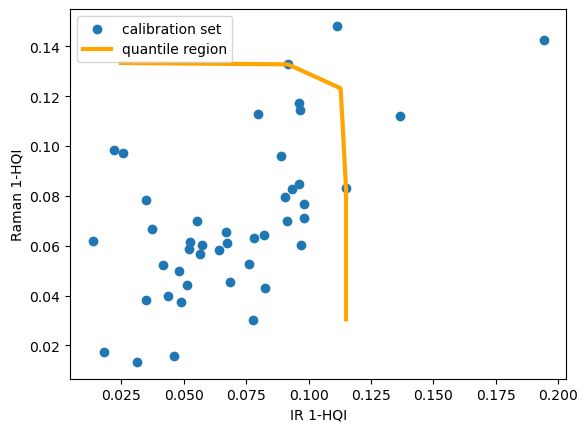

In [34]:
alpha = .1
beta, q_array, U = calibrate_beta_mv(alpha, quant_smx_list, quant_labels)
#U = np.array([u/np.linalg.norm(u) for u in U])
n = rest_smx_list[0].shape[0]
t = np.max([project_u_mv(rest_smx_list, U[th,:])[0][np.arange(n),rest_labels]/q for th, q in enumerate(q_array)], 0)



#plt.scatter(smx_all_IR[np.arange(label_ir.shape[0]),label_ir],
#            smx_all_Raman[np.arange(label_ir.shape[0]),label_ir], 
#            label='calibration set')

plt.scatter(quant_smx_list[0][np.arange(quant_labels.shape[0]),quant_labels],
            quant_smx_list[1][np.arange(quant_labels.shape[0]),quant_labels], 
            label='calibration set')

#plt.scatter(smx_all_IR_rest.min(1),
#            smx_all_Raman_rest.min(1))

#plt.scatter(U[:,0],
#            U[:,1])

#plt.scatter(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t,
#            rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t, 
#            label='quantile region')

idx_quant_reg = np.argsort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_x = np.sort(rest_smx_list[0][np.arange(rest_labels.shape[0]),rest_labels]/t)#[::-1]
quant_reg_y = (rest_smx_list[1][np.arange(rest_labels.shape[0]),rest_labels]/t)[idx_quant_reg]

plt.plot(quant_reg_x,
         quant_reg_y, 
         label='quantile region',
         c='orange',
         linewidth=3.0
     )

plt.xlabel("IR 1-HQI")
plt.ylabel("Raman 1-HQI")

plt.legend()

In [35]:
quant_reg_x

array([0.02482938, 0.02731248, 0.03171062, 0.03254557, 0.0353785 ,
       0.03788388, 0.0448751 , 0.04705683, 0.04942199, 0.05082461,
       0.05407759, 0.05459236, 0.05532919, 0.05763405, 0.06521729,
       0.07233602, 0.0751039 , 0.07547927, 0.0757642 , 0.07776826,
       0.07879767, 0.08191546, 0.08303145, 0.0854824 , 0.08860789,
       0.08881747, 0.08885925, 0.08886099, 0.09153504, 0.09159644,
       0.09236862, 0.09288355, 0.09300992, 0.09392833, 0.09452203,
       0.09463416, 0.09585824, 0.09703899, 0.09969603, 0.09998404,
       0.10046123, 0.10090205, 0.10177166, 0.10327153, 0.10392597,
       0.10438846, 0.10466281, 0.10484697, 0.10740629, 0.10837777,
       0.10946964, 0.10948994, 0.11020789, 0.11043801, 0.11069766,
       0.11106985, 0.11141449, 0.11268455, 0.11282305, 0.11282734,
       0.11282958, 0.11286057, 0.11287915, 0.11289316, 0.11293439,
       0.11298938, 0.11299197, 0.11305351, 0.1130885 , 0.11308934,
       0.11313703, 0.11319335, 0.1132018 , 0.11323604, 0.11330

(array([32., 66., 80., 28., 12.,  4.,  0.,  1.,  0.,  1.]),
 array([0.0099437 , 0.03465428, 0.05936485, 0.08407543, 0.108786  ,
        0.13349657, 0.15820715, 0.18291772, 0.20762829, 0.23233887,
        0.25704944]),
 <BarContainer object of 10 artists>)

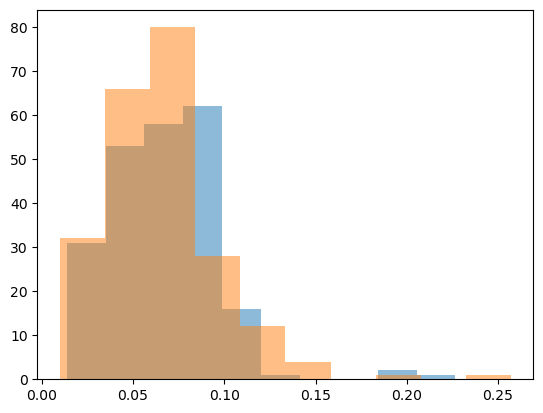

In [36]:
cal_x = smx_all_IR[np.arange(label_ir.shape[0]),label_ir]
cal_y = smx_all_Raman[np.arange(label_ir.shape[0]),label_ir]

plt.hist(cal_x, alpha=.5)
plt.hist(cal_y, alpha=.5)

array(['NaNO3'], dtype=object)

In [99]:
prediction_sets[0]

array([False,  True, False, False, False, False])

In [38]:
np.quantile(smx_all_Raman[np.arange(label_ir.shape[0]),label_ir], .9)

0.09900734526057017

In [124]:
[(list(np.array(label_table.loc[x,'polymer'])),y,z) for x,y,z in zip(prediction_sets, y_ir_rest, notes_mix_std_rest) if z != '']


[(['sucrose'], 'LOW SIGNAL', 'PSL AND SOMETHING ELSE? SCR?'),
 (['NaNO3', 'sucrose'], 'LOW SIGNAL', 'AS AND LDPE?'),
 (['NaNO3', 'PE', 'PP', 'sucrose'], 'LOW SIGNAL', 'PP AND LDPE?'),
 (['NH2SO4', 'NaNO3', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE, LDPE?'),
 (['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'ODD PEAKS IN PTIR'),
 (['NH2SO4', 'NaNO3', 'PSL', 'sucrose'], 'LOW SIGNAL', 'SCR AND SN?'),
 (['NaNO3', 'sucrose'], 'LOW SIGNAL', 'PEAKS UNIDENTIFIED, MIX?'),
 (['NH2SO4', 'PE', 'PP', 'PSL', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE'),
 (['NaNO3', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE'),
 (['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'ODD PEAKS IN PTIR, FLUORESCENCE'),
 (['NaNO3', 'sucrose'], 'LOW SIGNAL', 'ODD PEAKS IN RAMAN, FLUORESCENCE'),
 (['NaNO3', 'PP', 'sucrose'], 'LOW SIGNAL', 'ODD PEAKS, FLUORESCENCE'),
 (['NH2SO4', 'NaNO3', 'PE', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['NH2SO4', 'Na

In [125]:
[(list(np.array(label_table.loc[x,'polymer'])),y,z) for x,y,z in zip(prediction_sets_raman, y_ir_rest, notes_mix_std_rest) if z != '']


[(['sucrose'], 'LOW SIGNAL', 'PSL AND SOMETHING ELSE? SCR?'),
 (['NH2SO4', 'NaNO3', 'PE', 'sucrose'], 'LOW SIGNAL', 'AS AND LDPE?'),
 (['sucrose'], 'LOW SIGNAL', 'PP AND LDPE?'),
 (['NaNO3', 'PSL', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE, LDPE?'),
 (['sucrose'], 'LOW SIGNAL', 'ODD PEAKS IN PTIR'),
 (['sucrose'], 'LOW SIGNAL', 'SCR AND SN?'),
 (['sucrose'], 'LOW SIGNAL', 'PEAKS UNIDENTIFIED, MIX?'),
 (['sucrose'], 'LOW SIGNAL', 'FLUORESCENCE'),
 (['PE', 'PP', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE'),
 (['NaNO3', 'PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'ODD PEAKS IN PTIR, FLUORESCENCE'),
 (['sucrose'], 'LOW SIGNAL', 'ODD PEAKS IN RAMAN, FLUORESCENCE'),
 (['sucrose'], 'LOW SIGNAL', 'ODD PEAKS, FLUORESCENCE'),
 (['NaNO3', 'PE', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['sucrose'], 'LOW SIGNAL', 'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['PP', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['PSL', 'sucrose'], 'L

In [126]:
[(list(np.array(label_table.loc[x,'polymer'])),y, z) for x,y,z in zip(prediction_sets_mvcp, y_ir_rest, notes_mix_std_rest) if z != '']



[(['sucrose'], 'LOW SIGNAL', 'PSL AND SOMETHING ELSE? SCR?'),
 (['NH2SO4', 'NaNO3', 'PE', 'sucrose'], 'LOW SIGNAL', 'AS AND LDPE?'),
 (['sucrose'], 'LOW SIGNAL', 'PP AND LDPE?'),
 (['NaNO3', 'PSL', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE, LDPE?'),
 (['sucrose'], 'LOW SIGNAL', 'ODD PEAKS IN PTIR'),
 (['sucrose'], 'LOW SIGNAL', 'SCR AND SN?'),
 (['sucrose'], 'LOW SIGNAL', 'PEAKS UNIDENTIFIED, MIX?'),
 (['sucrose'], 'LOW SIGNAL', 'FLUORESCENCE'),
 (['PE', 'PP', 'sucrose'], 'LOW SIGNAL', 'FLUORESCENCE'),
 (['NaNO3', 'PP', 'sucrose'], 'LOW SIGNAL', 'ODD PEAKS IN PTIR, FLUORESCENCE'),
 (['sucrose'], 'LOW SIGNAL', 'ODD PEAKS IN RAMAN, FLUORESCENCE'),
 (['sucrose'], 'LOW SIGNAL', 'ODD PEAKS, FLUORESCENCE'),
 (['NaNO3', 'PSL', 'sucrose'],
  'LOW SIGNAL',
  'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['sucrose'], 'LOW SIGNAL', 'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['PP', 'sucrose'], 'LOW SIGNAL', 'NOT ENOUGH IDENTIFIABLE PEAKS IN PTIR'),
 (['PSL', 'sucrose'], 'LOW SIGNAL', 'NOT ENOUGH IDEN

In [193]:
df_res = pd.DataFrame(pd.DataFrame(set_size).mean()).reset_index()
df_res['cp'] = [s[:-1] for s in df_res['index']]
df_res['M'] = [s[-1] for s in df_res['index']]
del df_res['index']
df_res = df_res.pivot(index='M', columns='cp', values=0)#.loc[:,['view_IR','view_Raman', 'mvcp']]
df_res = df_res.reset_index(drop=True)
df_res

cp,mvcp,view_IR
0,0.938503,1.510695


In [47]:
for x,y,z in zip([1,2,3],['a','b','c'],['d','e','f']):
    print(x,y,z)

1 a d
2 b e
3 c f
